# Alternative Hebrew Registers: Torah vs Mishnah vs Zohar

## Motivation

The previous decipherment models use **Biblical Hebrew (Torah)** as the target corpus. If the Voynich author were a Jewish doctor/kabbalist from Northern Italy (15th century), their writing would be a different register:

- **Mishnah** (Mishnaic Hebrew, halakhic) — Vilna 1913, ~188K words, 63 tractates
- **Zohar** (Zoharic Aramaic, kabbalistic) — Sulam 1945, ~580K words, 50 parashot

The current ceiling of 68% n-gram and 3-5 roots could be an artefact of training the LM against the wrong register.

**Pipeline:** same neural_v2 (LSTM + EM multi-seed + MCMC) × 3 registers.

In [1]:
# ── Cell 1: Imports ──────────────────────────────────────────────────
import re, math, random, json, warnings, time, copy
from collections import Counter, defaultdict
from itertools import combinations
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import requests
from scipy.spatial.distance import jensenshannon
from tqdm.notebook import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.dpi': 130, 'savefig.dpi': 180,
    'font.size': 10, 'axes.titlesize': 11,
    'figure.facecolor': 'white',
})

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')
print('Imports OK')

Device: cuda
Imports OK


In [2]:
# ── Cell 2: Load Voynich corpus ─────────────────────────────────────
STA_PATH = 'corpus/voynich_sta.txt'

def parsear_sta_completo(filepath):
    tokens = []
    with open(filepath, 'r', encoding='utf-8') as f:
        for linea in f:
            linea = linea.strip()
            if not linea or linea.startswith('#'):
                continue
            if re.match(r'^<[^>]+>\s*<!', linea):
                continue
            match = re.match(r'^<[^>]+>\s+(.*)', linea)
            if not match:
                continue
            texto = match.group(1).strip()
            texto = re.sub(r'\{[^}]*\}', '', texto)
            texto = re.sub(r'<[^>]*>',   '', texto)
            texto = re.sub(r'-',          '.', texto)
            texto = texto.strip()
            if not texto:
                continue
            for palabra_raw in texto.split('.'):
                palabra_raw = palabra_raw.strip()
                if not palabra_raw:
                    continue
                glifos = re.findall(r'[A-Z][0-9a-z]', palabra_raw)
                if glifos:
                    tokens.extend(glifos)
                    tokens.append('.')
    return tokens


def tokens_a_palabras(tokens):
    palabras, actual = [], []
    for t in tokens:
        if t == '.':
            if actual:
                palabras.append(actual)
                actual = []
        else:
            actual.append(t)
    if actual:
        palabras.append(actual)
    return palabras


def construir_matriz_transicion_intrapalabra(palabras):
    all_glyphs = sorted({g for p in palabras for g in p})
    index = {g: i for i, g in enumerate(all_glyphs)}
    n = len(all_glyphs)
    M_raw = np.zeros((n, n))
    for palabra in palabras:
        for i in range(len(palabra) - 1):
            r, c = index[palabra[i]], index[palabra[i + 1]]
            M_raw[r, c] += 1
    row_sums = M_raw.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1
    M_prob = M_raw / row_sums
    return M_raw, M_prob, all_glyphs, index


# ── Parse ──
tokens = parsear_sta_completo(STA_PATH)
palabras = tokens_a_palabras(tokens)
N_VOYNICH = len(palabras)
VOCAB = sorted({g for p in palabras for g in p})

# Glyph frequency & positional stats
glyph_freq = Counter(g for p in palabras for g in p)
glyph_stats = {}
for g in VOCAB:
    pos_ini, pos_fin, pos_med, total = 0, 0, 0, 0
    for p in palabras:
        for i, gl in enumerate(p):
            if gl == g:
                total += 1
                if len(p) == 1:
                    pos_ini += 0.5; pos_fin += 0.5
                elif i == 0:
                    pos_ini += 1
                elif i == len(p) - 1:
                    pos_fin += 1
                else:
                    pos_med += 1
    pt = pos_ini + pos_fin + pos_med
    glyph_stats[g] = {
        'total': total,
        'pos_inicio': pos_ini, 'pos_fin': pos_fin, 'pos_medio': pos_med,
        'pct_onset': pos_ini / pt if pt > 0 else 0,
        'pct_coda': pos_fin / pt if pt > 0 else 0,
        'pct_nuclear': pos_med / pt if pt > 0 else 0,
    }

# Syllable segmentation for role classification
M_raw, M_prob, all_gl, idx_gl = construir_matriz_transicion_intrapalabra(palabras)

# Classify C/V via onset/coda tendency
glyph_role = {}
for g in VOCAB:
    s = glyph_stats[g]
    if s['pct_onset'] > 0.55:
        glyph_role[g] = 'C'
    elif s['pct_coda'] > 0.55:
        glyph_role[g] = 'V'
    else:
        glyph_role[g] = '?'

n_C = sum(1 for v in glyph_role.values() if v == 'C')
n_V = sum(1 for v in glyph_role.values() if v == 'V')
n_Q = sum(1 for v in glyph_role.values() if v == '?')

print(f'Voynich: {N_VOYNICH:,} words, {len(VOCAB)} glyphs')
print(f'Roles: C={n_C}, V={n_V}, ?={n_Q}')
wl = [len(p) for p in palabras]
print(f'Word length: mean={np.mean(wl):.2f}, median={np.median(wl):.0f}')

Voynich: 37,087 words, 166 glyphs
Roles: C=42, V=26, ?=98
Word length: mean=4.24, median=4


In [3]:
# ── Cell 3: Download 3 corpora ──────────────────────────────────────

def descargar_hebreo():
    libros = ['Genesis', 'Exodus', 'Leviticus', 'Numbers', 'Deuteronomy']
    base_url = ('https://raw.githubusercontent.com/Sefaria/Sefaria-Export/'
                'master/json/Tanakh/Torah/{}/Hebrew/Tanach%20with%20Text%20Only.json')
    todas_palabras = []
    for libro in libros:
        url = base_url.format(libro)
        print(f'  Downloading {libro}...')
        resp = requests.get(url, timeout=30)
        resp.raise_for_status()
        data = resp.json()
        for capitulo in data['text']:
            for versiculo in capitulo:
                texto = re.sub(r'[\u0591-\u05C7]', '', versiculo)
                pals = re.findall(r'[\u05D0-\u05EA]+', texto)
                for p in pals:
                    chars = list(p)
                    if 2 <= len(chars) <= 15:
                        todas_palabras.append(chars)
    print(f'  Torah total: {len(todas_palabras):,} words')
    return todas_palabras


def descargar_mishnah():
    SEDARIM = {
        'Seder Zeraim': ['Berakhot', 'Peah', 'Demai', 'Kilayim', 'Sheviit',
                         'Terumot', 'Maasrot', 'Maaser Sheni', 'Challah', 'Orlah', 'Bikkurim'],
        'Seder Moed': ['Shabbat', 'Eruvin', 'Pesachim', 'Shekalim', 'Yoma',
                       'Sukkah', 'Beitzah', 'Rosh Hashanah', "Ta'anit", 'Megillah',
                       'Moed Katan', 'Chagigah'],
        'Seder Nashim': ['Yevamot', 'Ketubot', 'Nedarim', 'Nazir', 'Sotah',
                         'Gittin', 'Kiddushin'],
        'Seder Nezikin': ['Bava Kamma', 'Bava Metzia', 'Bava Batra', 'Sanhedrin',
                          'Makkot', 'Shevuot', 'Eduyot', 'Avodah Zarah', 'Horayot',
                          'Pirkei Avot'],
        'Seder Kodashim': ['Zevachim', 'Menachot', 'Chullin', 'Bekhorot', 'Arakhin',
                           'Temurah', 'Keritot', 'Meilah', 'Tamid', 'Middot', 'Kinnim'],
        'Seder Tahorot': ['Kelim', 'Oholot', 'Negaim', 'Parah', 'Tahorot',
                          'Mikvaot', 'Niddah', 'Makhshirin', 'Zavim', 'Tevul Yom',
                          'Yadayim', 'Oktzin'],
    }
    base_url = ('https://raw.githubusercontent.com/Sefaria/Sefaria-Export/'
                'master/json/Mishnah/{}/'
                'Mishnah%20{}/Hebrew/'
                'Mishnah%2C%20ed.%20Romm%2C%20Vilna%201913.json')
    todas_palabras = []
    failed = []
    for seder, tractates in SEDARIM.items():
        seder_url = seder.replace(' ', '%20')
        for tractate in tractates:
            tractate_url = tractate.replace(' ', '%20').replace("'", '%27')
            url = base_url.format(seder_url, tractate_url)
            try:
                resp = requests.get(url, timeout=30)
                resp.raise_for_status()
                data = resp.json()
                for capitulo in data['text']:
                    if isinstance(capitulo, list):
                        for mishnah in capitulo:
                            if isinstance(mishnah, str):
                                texto = re.sub(r'[\u0591-\u05C7]', '', mishnah)
                                pals = re.findall(r'[\u05D0-\u05EA]+', texto)
                                for p in pals:
                                    chars = list(p)
                                    if 2 <= len(chars) <= 15:
                                        todas_palabras.append(chars)
                            elif isinstance(mishnah, list):
                                for item in mishnah:
                                    if isinstance(item, str):
                                        texto = re.sub(r'[\u0591-\u05C7]', '', item)
                                        pals = re.findall(r'[\u05D0-\u05EA]+', texto)
                                        for p in pals:
                                            chars = list(p)
                                            if 2 <= len(chars) <= 15:
                                                todas_palabras.append(chars)
                    elif isinstance(capitulo, str):
                        texto = re.sub(r'[\u0591-\u05C7]', '', capitulo)
                        pals = re.findall(r'[\u05D0-\u05EA]+', texto)
                        for p in pals:
                            chars = list(p)
                            if 2 <= len(chars) <= 15:
                                todas_palabras.append(chars)
            except Exception as e:
                failed.append((tractate, str(e)))
        print(f'  {seder}: {len(todas_palabras):,} cumulative')
    if failed:
        print(f'  ⚠ Failed: {len(failed)} tractates: {[f[0] for f in failed]}')
    print(f'  Mishnah total: {len(todas_palabras):,} words')
    return todas_palabras


def descargar_zohar():
    url = ('https://raw.githubusercontent.com/Sefaria/Sefaria-Export/'
           'master/json/Kabbalah/Zohar/Zohar/Hebrew/'
           'Sulam%20Edition%2C%20Jerusalem%201945.json')
    print(f'  Downloading Zohar (may take a while, ~8MB)...')
    resp = requests.get(url, timeout=120)
    resp.raise_for_status()
    data = resp.json()
    todas_palabras = []
    text_data = data['text']
    if isinstance(text_data, dict):
        for parashah, chapters in text_data.items():
            if not isinstance(chapters, list):
                continue
            for chapter in chapters:
                if isinstance(chapter, list):
                    for paragraph in chapter:
                        if isinstance(paragraph, str):
                            # Strip HTML tags
                            texto = re.sub(r'<[^>]*>', '', paragraph)
                            # Strip editorial comments (נ"א: ...)
                            texto = re.sub(r'\([^)]*\)', '', texto)
                            # Strip nikkud/cantillation
                            texto = re.sub(r'[\u0591-\u05C7]', '', texto)
                            pals = re.findall(r'[\u05D0-\u05EA]+', texto)
                            for p in pals:
                                chars = list(p)
                                if 2 <= len(chars) <= 15:
                                    todas_palabras.append(chars)
                        elif isinstance(paragraph, list):
                            for item in paragraph:
                                if isinstance(item, str):
                                    texto = re.sub(r'<[^>]*>', '', item)
                                    texto = re.sub(r'\([^)]*\)', '', texto)
                                    texto = re.sub(r'[\u0591-\u05C7]', '', texto)
                                    pals = re.findall(r'[\u05D0-\u05EA]+', texto)
                                    for p in pals:
                                        chars = list(p)
                                        if 2 <= len(chars) <= 15:
                                            todas_palabras.append(chars)
                elif isinstance(chapter, str):
                    texto = re.sub(r'<[^>]*>', '', chapter)
                    texto = re.sub(r'\([^)]*\)', '', texto)
                    texto = re.sub(r'[\u0591-\u05C7]', '', texto)
                    pals = re.findall(r'[\u05D0-\u05EA]+', texto)
                    for p in pals:
                        chars = list(p)
                        if 2 <= len(chars) <= 15:
                            todas_palabras.append(chars)
    elif isinstance(text_data, list):
        for chapter in text_data:
            if isinstance(chapter, list):
                for item in chapter:
                    if isinstance(item, str):
                        texto = re.sub(r'<[^>]*>', '', item)
                        texto = re.sub(r'\([^)]*\)', '', texto)
                        texto = re.sub(r'[\u0591-\u05C7]', '', texto)
                        pals = re.findall(r'[\u05D0-\u05EA]+', texto)
                        for p in pals:
                            chars = list(p)
                            if 2 <= len(chars) <= 15:
                                todas_palabras.append(chars)
                    elif isinstance(item, list):
                        for sub in item:
                            if isinstance(sub, str):
                                texto = re.sub(r'<[^>]*>', '', sub)
                                texto = re.sub(r'\([^)]*\)', '', texto)
                                texto = re.sub(r'[\u0591-\u05C7]', '', texto)
                                pals = re.findall(r'[\u05D0-\u05EA]+', texto)
                                for p in pals:
                                    chars = list(p)
                                    if 2 <= len(chars) <= 15:
                                        todas_palabras.append(chars)
    print(f'  Zohar total: {len(todas_palabras):,} words')
    return todas_palabras


# ── Download all 3 corpora ──
print('Downloading Torah...')
torah_words_full = descargar_hebreo()
print('\nDownloading Mishnah...')
mishnah_words_full = descargar_mishnah()
print('\nDownloading Zohar...')
zohar_words_full = descargar_zohar()

# ── Subsample to N_VOYNICH ──
rng_sub = np.random.default_rng(42)
HEBREW_VOWELS = set('אהוי')

corpora_full = {
    'Torah': torah_words_full,
    'Mishnah': mishnah_words_full,
    'Zohar': zohar_words_full,
}

corpora = {}
for name, words_full in corpora_full.items():
    if len(words_full) > N_VOYNICH:
        idx = rng_sub.choice(len(words_full), size=N_VOYNICH, replace=False)
        words = [words_full[i] for i in sorted(idx)]
    else:
        words = words_full
    corpora[name] = words

# ── Statistics ──
print(f'\n{"Corpus":<12} {"Full":>10} {"Sample":>10} {"Vocab":>8} {"Mean WL":>10}')
print('-' * 55)
for name, words in corpora.items():
    chars = sorted(set(c for w in words for c in w))
    mean_wl = np.mean([len(w) for w in words])
    print(f'{name:<12} {len(corpora_full[name]):>10,} {len(words):>10,} {len(chars):>8} {mean_wl:>10.2f}')

# ── Grammar anchors (from Voynich structure, same for all registers) ──
HEBREW_PREFIXES = set('והבכלמש')
HEBREW_SUFFIXES = set('התםןך')
HEBREW_ROOT_CONSONANTS = set('אבגדהוזחטיכלמנסעפצקרשת') - HEBREW_PREFIXES - HEBREW_SUFFIXES

GRAMMAR_ANCHORS = {
    'D1': HEBREW_PREFIXES,
    'K1': HEBREW_PREFIXES | {'ש'},
    'L1': {'ל', 'ה', 'ב', 'מ'},
    'Q1': HEBREW_ROOT_CONSONANTS,
    'Q2': HEBREW_ROOT_CONSONANTS,
    'A2': HEBREW_SUFFIXES,
    'C1': HEBREW_SUFFIXES,
}

def build_glyph_grammar_roles(palabras, glyph_stats, VOCAB):
    glyph_grammar_role = {}
    direct_rules = {
        'D1': 'prefix', 'K1': 'classifier', 'L1': 'prefix',
        'Q1': 'root', 'Q2': 'root',
        'A2': 'suffix', 'C1': 'suffix',
    }
    for g in VOCAB:
        if g in direct_rules:
            glyph_grammar_role[g] = direct_rules[g]
            continue
        s = glyph_stats.get(g, {})
        total = s.get('total', 0)
        if total < 10:
            continue
        pos_ini = s.get('pos_inicio', 0)
        pos_fin = s.get('pos_fin', 0)
        pos_med = s.get('pos_medio', 0)
        pos_total = pos_ini + pos_fin + pos_med
        if pos_total == 0:
            continue
        pct_onset = s.get('pct_onset', 0)
        pct_coda = s.get('pct_coda', 0)
        pct_nuclear = s.get('pct_nuclear', 0)
        r_ini = pos_ini / pos_total
        r_fin = pos_fin / pos_total
        if pct_onset > 0.50 and r_ini > 0.50:
            glyph_grammar_role[g] = 'prefix'
        elif pct_coda > 0.50 and r_fin > 0.50:
            glyph_grammar_role[g] = 'suffix'
        elif pct_nuclear > 0.40:
            glyph_grammar_role[g] = 'root'
    role_to_anchor = {
        'prefix': HEBREW_PREFIXES,
        'classifier': HEBREW_PREFIXES | {'ש'},
        'root': HEBREW_ROOT_CONSONANTS,
        'suffix': HEBREW_SUFFIXES,
    }
    glyph_anchor_sets = {}
    for g, role in glyph_grammar_role.items():
        glyph_anchor_sets[g] = role_to_anchor.get(role, set())
    return glyph_grammar_role, glyph_anchor_sets

glyph_grammar_role, glyph_anchor_sets = build_glyph_grammar_roles(
    palabras, glyph_stats, VOCAB)

role_counts = Counter(glyph_grammar_role.values())
print(f'\nGrammar anchors: {len(glyph_grammar_role)} glyphs')
for role, cnt in sorted(role_counts.items(), key=lambda x: -x[1]):
    print(f'  {role}: {cnt}')

  Torah total: 80,051 words

  Seder Zeraim: 23,232 cumulative
  Seder Moed: 51,351 cumulative
  Seder Nashim: 80,360 cumulative
  Seder Nezikin: 112,173 cumulative
  Seder Kodashim: 144,276 cumulative
  Seder Tahorot: 186,577 cumulative
  ⚠ Failed: 1 tractates: ['Pirkei Avot']
  Mishnah total: 186,577 words

  Zohar total: 768,375 words

Corpus             Full     Sample    Vocab    Mean WL
-------------------------------------------------------
Torah            80,051     37,087       27       3.81
Mishnah         186,577     37,087       27       4.10
Zohar           768,375     37,087       27       4.21

Grammar anchors: 54 glyphs
  root: 28
  suffix: 13
  prefix: 12
  classifier: 1


In [4]:
# ── Cell 4: NeuralCharLM — LSTM architecture ─────────────────────────

class CharDataset(Dataset):
    def __init__(self, words, char2idx):
        self.samples = []
        bos = char2idx['<w>']
        eos = char2idx['</w>']
        for word in words:
            indices = [bos, bos] + [char2idx.get(c, char2idx.get('<unk>', 0)) for c in word] + [eos]
            for i in range(2, len(indices)):
                ctx = indices[i-2:i]
                target = indices[i]
                self.samples.append((ctx, target))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        ctx, target = self.samples[idx]
        return torch.tensor(ctx, dtype=torch.long), torch.tensor(target, dtype=torch.long)


class NeuralCharLM(nn.Module):
    def __init__(self, vocab_size, embed_dim=32, hidden_dim=192, n_layers=2, dropout=0.2):
        super().__init__()
        self.vocab_size = vocab_size
        self.embed_dim = embed_dim
        self.hidden_dim = hidden_dim
        self.n_layers = n_layers
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, num_layers=n_layers,
                           dropout=dropout if n_layers > 1 else 0.0,
                           batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, vocab_size)
        self.char2idx = None
        self.idx2char = None

    def forward(self, x, hidden=None):
        emb = self.dropout(self.embedding(x))
        out, hidden = self.lstm(emb, hidden)
        out = self.dropout(out)
        logits = self.fc(out)
        return logits, hidden

    def log_prob(self, word, temperature=1.0):
        self.eval()
        with torch.no_grad():
            bos = self.char2idx['<w>']
            eos = self.char2idx['</w>']
            unk = self.char2idx.get('<unk>', 0)
            indices = [bos, bos] + [self.char2idx.get(c, unk) for c in word] + [eos]
            total_lp = 0.0
            for i in range(2, len(indices)):
                ctx = torch.tensor([[indices[i-2], indices[i-1]]], device=DEVICE)
                logits, _ = self.forward(ctx)
                logits_t = logits[0, -1, :] / temperature
                log_probs = torch.log_softmax(logits_t, dim=0)
                total_lp += log_probs[indices[i]].item() / math.log(2)
            return total_lp

    def batch_log_prob(self, words, temperature=1.0):
        self.eval()
        bos = self.char2idx['<w>']
        eos = self.char2idx['</w>']
        unk = self.char2idx.get('<unk>', 0)
        with torch.no_grad():
            all_ctx = []
            all_tgt = []
            word_boundaries = [0]
            for word in words:
                seq = [bos, bos] + [self.char2idx.get(c, unk) for c in word] + [eos]
                for i in range(2, len(seq)):
                    all_ctx.append([seq[i-2], seq[i-1]])
                    all_tgt.append(seq[i])
                word_boundaries.append(len(all_ctx))
            n_total = len(all_ctx)
            if n_total == 0:
                return np.zeros(len(words))
            ctx_t = torch.tensor(all_ctx, device=DEVICE)
            tgt_t = torch.tensor(all_tgt, device=DEVICE)
            CHUNK = 16384
            all_lps = []
            for start in range(0, n_total, CHUNK):
                end = min(start + CHUNK, n_total)
                logits, _ = self.forward(ctx_t[start:end])
                logits_last = logits[:, -1, :] / temperature
                log_p = torch.log_softmax(logits_last, dim=-1)
                target_lp = log_p.gather(1, tgt_t[start:end].unsqueeze(1)).squeeze(1)
                all_lps.append(target_lp)
            all_lps = torch.cat(all_lps).cpu().numpy() / math.log(2)
            word_lps = np.zeros(len(words))
            for wi in range(len(words)):
                start = word_boundaries[wi]
                end = word_boundaries[wi + 1]
                if start < end:
                    word_lps[wi] = all_lps[start:end].sum()
            return word_lps

    def perplexity(self, words, temperature=1.0):
        self.eval()
        word_lps = self.batch_log_prob(words, temperature)
        total_lp = word_lps.sum()
        total_n = sum(len(w) + 1 for w in words)
        if total_n == 0:
            return float('inf')
        return 2.0 ** (-total_lp / total_n)

print('NeuralCharLM class defined')

NeuralCharLM class defined



Training LM: Torah (37,087 words)
  Train: 29,670, Val: 7,417, Vocab: 31
  Epoch  1: train=2.3444, val=2.1394
  Epoch  5: train=2.0598, val=2.0296
  Epoch 10: train=2.0325, val=2.0152
  Epoch 15: train=2.0208, val=2.0099
  Epoch 20: train=2.0107, val=2.0057
  Epoch 25: train=2.0033, val=2.0037
  Epoch 30: train=2.0013, val=2.0031
  Best val_loss: 2.0031 (49.2s)

Training LM: Mishnah (37,087 words)
  Train: 29,670, Val: 7,417, Vocab: 31
  Epoch  1: train=2.4261, val=2.2355
  Epoch  5: train=2.1589, val=2.1298
  Epoch 10: train=2.1311, val=2.1167
  Epoch 15: train=2.1194, val=2.1111
  Epoch 20: train=2.1117, val=2.1072
  Epoch 25: train=2.1042, val=2.1062
  Epoch 30: train=2.0992, val=2.1060
  Best val_loss: 2.1060 (53.2s)

Training LM: Zohar (37,087 words)
  Train: 29,670, Val: 7,417, Vocab: 31
  Epoch  1: train=2.4196, val=2.2570
  Epoch  5: train=2.1546, val=2.1447
  Epoch 10: train=2.1302, val=2.1315
  Epoch 15: train=2.1158, val=2.1247
  Epoch 20: train=2.1089, val=2.1208
  Epoch 2

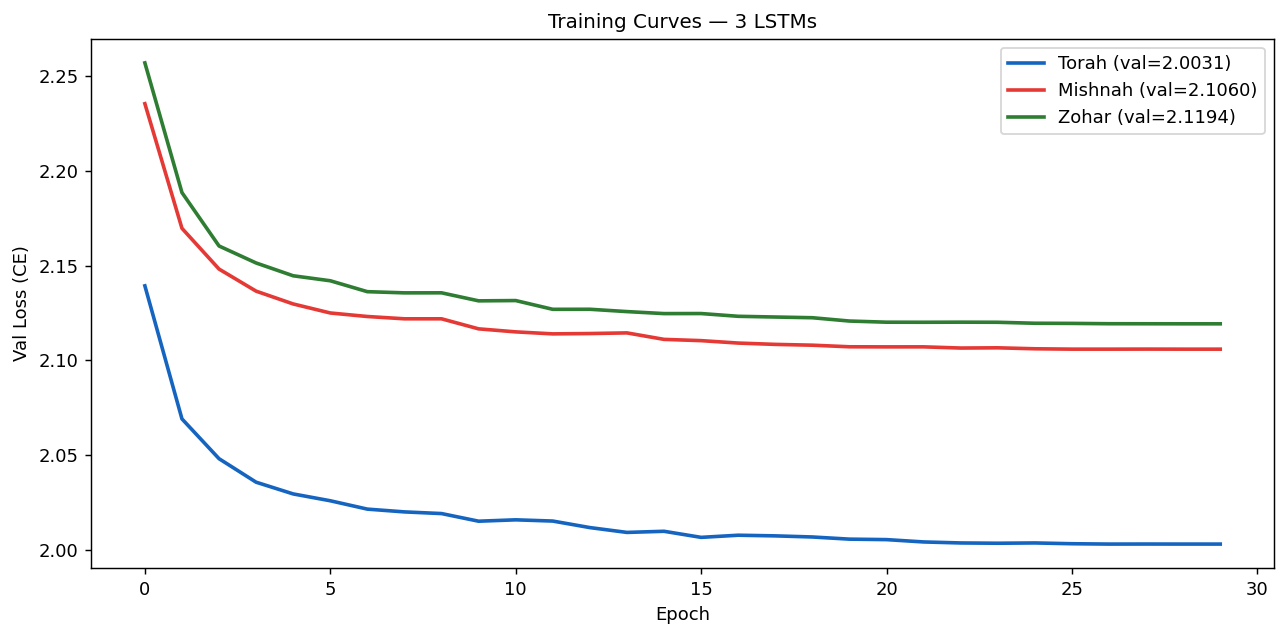


── Summary LMs ──
  Torah: val_loss=2.0031, chars=27
  Mishnah: val_loss=2.1060, chars=27
  Zohar: val_loss=2.1194, chars=27


In [5]:
# ── Cell 5: Train 3 LSTMs ─────────────────────────────────────────

N_EPOCHS = 30
PATIENCE = 5

trained_lms = {}

for reg_name, reg_words in corpora.items():
    print(f'\n{"="*60}')
    print(f'Training LM: {reg_name} ({len(reg_words):,} words)')
    print(f'{"="*60}')

    # Build char vocab
    all_chars = sorted(set(c for w in reg_words for c in w))
    special_tokens = ['<pad>', '<w>', '</w>', '<unk>']
    char_vocab = special_tokens + all_chars
    char2idx = {c: i for i, c in enumerate(char_vocab)}
    idx2char = {i: c for c, i in char2idx.items()}

    # C/V classification
    char_role = {c: 'V' if c in HEBREW_VOWELS else 'C' for c in all_chars}

    # Train/val split
    rng_split = np.random.default_rng(42)
    n_val = int(0.2 * len(reg_words))
    perm = rng_split.permutation(len(reg_words))
    val_idx = set(perm[:n_val])
    train_words = [reg_words[i] for i in range(len(reg_words)) if i not in val_idx]
    val_words = [reg_words[i] for i in range(len(reg_words)) if i in val_idx]
    print(f'  Train: {len(train_words):,}, Val: {len(val_words):,}, Vocab: {len(char_vocab)}')

    # Datasets
    train_dataset = CharDataset(train_words, char2idx)
    val_dataset = CharDataset(val_words, char2idx)
    train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True, num_workers=0)
    val_loader = DataLoader(val_dataset, batch_size=256, shuffle=False, num_workers=0)

    # Model
    neural_lm = NeuralCharLM(len(char_vocab), embed_dim=32, hidden_dim=192,
                              n_layers=2, dropout=0.2).to(DEVICE)
    neural_lm.char2idx = char2idx
    neural_lm.idx2char = idx2char

    optimizer = optim.AdamW(neural_lm.parameters(), lr=2e-3, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=N_EPOCHS)
    criterion = nn.CrossEntropyLoss(ignore_index=char2idx['<pad>'])

    best_val_loss = float('inf')
    patience_counter = 0
    train_losses = []
    val_losses = []

    t0 = time.time()
    for epoch in range(N_EPOCHS):
        neural_lm.train()
        epoch_loss, n_batches = 0.0, 0
        for ctx_batch, target_batch in train_loader:
            ctx_batch = ctx_batch.to(DEVICE)
            target_batch = target_batch.to(DEVICE)
            optimizer.zero_grad()
            logits, _ = neural_lm(ctx_batch)
            loss = criterion(logits[:, -1, :], target_batch)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(neural_lm.parameters(), 1.0)
            optimizer.step()
            epoch_loss += loss.item()
            n_batches += 1
        train_loss = epoch_loss / max(n_batches, 1)
        train_losses.append(train_loss)

        neural_lm.eval()
        vl, n_vb = 0.0, 0
        with torch.no_grad():
            for ctx_batch, target_batch in val_loader:
                ctx_batch = ctx_batch.to(DEVICE)
                target_batch = target_batch.to(DEVICE)
                logits, _ = neural_lm(ctx_batch)
                loss = criterion(logits[:, -1, :], target_batch)
                vl += loss.item()
                n_vb += 1
        val_loss = vl / max(n_vb, 1)
        val_losses.append(val_loss)
        scheduler.step()

        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(f'  Epoch {epoch+1:2d}: train={train_loss:.4f}, val={val_loss:.4f}')

        if val_loss < best_val_loss - 1e-4:
            best_val_loss = val_loss
            patience_counter = 0
            best_state_dict = copy.deepcopy(neural_lm.state_dict())
        else:
            patience_counter += 1
            if patience_counter >= PATIENCE:
                print(f'  Early stopping at epoch {epoch+1}')
                break

    elapsed = time.time() - t0
    neural_lm.load_state_dict(best_state_dict)

    trained_lms[reg_name] = {
        'model': neural_lm,
        'char2idx': char2idx,
        'idx2char': idx2char,
        'target_chars': all_chars,
        'char_role': char_role,
        'val_loss': best_val_loss,
        'train_losses': train_losses,
        'val_losses': val_losses,
    }
    print(f'  Best val_loss: {best_val_loss:.4f} ({elapsed:.1f}s)')

# ── Training curves ──
fig, ax = plt.subplots(1, 1, figsize=(10, 5))
colors = {'Torah': '#1565C0', 'Mishnah': '#E53935', 'Zohar': '#2E7D32'}
for name, lm_data in trained_lms.items():
    ax.plot(lm_data['val_losses'], label=f'{name} (val={lm_data["val_loss"]:.4f})',
            color=colors[name], linewidth=2)
ax.set_xlabel('Epoch')
ax.set_ylabel('Val Loss (CE)')
ax.set_title('Training Curves — 3 LSTMs')
ax.legend()
plt.tight_layout()
plt.show()

print('\n── Summary LMs ──')
for name, d in trained_lms.items():
    print(f'  {name}: val_loss={d["val_loss"]:.4f}, chars={len(d["target_chars"])}')

In [6]:
# ── Cell 6: GlyphMappingState + Scoring + Root helpers ───────────────

class GlyphMappingState:
    def __init__(self, voynich_glyphs, target_chars, glyph_role=None, char_role=None):
        self.voynich_glyphs = list(voynich_glyphs)
        self.target_chars = list(target_chars)
        self.glyph_role = glyph_role or {}
        self.char_role = char_role or {}
        self.mapping = {}

    def set_mapping(self, mapping_dict):
        self.mapping = dict(mapping_dict)

    def propose_change(self, rng, constrained=True):
        new = GlyphMappingState(self.voynich_glyphs, self.target_chars,
                                self.glyph_role, self.char_role)
        new.mapping = dict(self.mapping)
        glyph = rng.choice(self.voynich_glyphs)
        if constrained and self.glyph_role.get(glyph) in ('C', 'V'):
            role = self.glyph_role[glyph]
            candidates = [c for c in self.target_chars if self.char_role.get(c) == role]
            if not candidates:
                candidates = self.target_chars
        else:
            candidates = self.target_chars
        new.mapping[glyph] = rng.choice(candidates)
        return new

    def propose_change_tracked(self, rng, constrained=True):
        new = GlyphMappingState(self.voynich_glyphs, self.target_chars,
                                self.glyph_role, self.char_role)
        new.mapping = dict(self.mapping)
        glyph = rng.choice(self.voynich_glyphs)
        if constrained and self.glyph_role.get(glyph) in ('C', 'V'):
            role = self.glyph_role[glyph]
            candidates = [c for c in self.target_chars if self.char_role.get(c) == role]
            if not candidates:
                candidates = self.target_chars
        else:
            candidates = self.target_chars
        new.mapping[glyph] = rng.choice(candidates)
        return new, glyph

    def apply_word(self, word_glyphs):
        return [self.mapping.get(g, '?') for g in word_glyphs]

    def apply_corpus(self, words):
        return [self.apply_word(w) for w in words]


def init_frequency_mapping(palabras, vocab_glyphs, target_chars, target_words,
                           glyph_role, char_role):
    gf = Counter(g for p in palabras for g in p)
    cf = Counter(c for w in target_words for c in w)
    mapping = {}
    for role in ('C', 'V', '?'):
        glyphs_r = sorted([g for g in vocab_glyphs if glyph_role.get(g, '?') == role],
                          key=lambda g: gf[g], reverse=True)
        if role == '?':
            chars_r = sorted(target_chars, key=lambda c: cf.get(c, 0), reverse=True)
        else:
            chars_r = sorted([c for c in target_chars if char_role.get(c) == role],
                             key=lambda c: cf.get(c, 0), reverse=True)
        if not chars_r:
            chars_r = sorted(target_chars, key=lambda c: cf.get(c, 0), reverse=True)
        for i, g in enumerate(glyphs_r):
            mapping[g] = chars_r[i % len(chars_r)]
    return mapping


def build_glyph_word_index(words):
    idx = defaultdict(list)
    for wi, word in enumerate(words):
        for g in set(word):
            idx[g].append(wi)
    return idx


def score_positional(mapping, glyph_role, char_role):
    n_ok = sum(1 for g, c in mapping.mapping.items()
               if glyph_role.get(g, '?') == char_role.get(c, '?')
               and glyph_role.get(g) != '?')
    n_total = sum(1 for g in mapping.mapping if glyph_role.get(g) != '?')
    return n_ok / max(n_total, 1)


def score_grammar(mapping_state, glyph_anchor_sets):
    if not glyph_anchor_sets:
        return 0.0
    n_anchored, score = 0, 0.0
    for g, anchor_set in glyph_anchor_sets.items():
        if not anchor_set:
            continue
        n_anchored += 1
        if mapping_state.mapping.get(g) in anchor_set:
            score += 1.0
        else:
            score -= 1.0
    return score / max(n_anchored, 1)


def score_entropy(mapping_state):
    char_counts = Counter(mapping_state.mapping.values())
    if len(char_counts) <= 1:
        return 0.0
    total = sum(char_counts.values())
    probs = np.array([c / total for c in char_counts.values()])
    probs = probs[probs > 0]
    H = -np.sum(probs * np.log2(probs))
    H_max = np.log2(len(char_counts))
    return H / H_max if H_max > 1e-10 else 0.0


def score_neural_lm_batch(mapping_state, words_sample, neural_lm, temperature=1.0):
    mapped = [mapping_state.apply_word(w) for w in words_sample]
    word_lps = neural_lm.batch_log_prob(mapped, temperature)
    return float(np.mean(word_lps)), word_lps


def score_cardinality(mapping_state, K_max=23):
    K = len(set(mapping_state.mapping.values()))
    if K >= K_max:
        return 0.0
    return -((K_max - K) ** 2)


def score_total_neural(mapping_state, words_sample, neural_lm, temperature,
                       glyph_role, char_role, glyph_anchor_sets,
                       w_lm=2.0, w_pos=0.5, w_card=0.5, w_ent=0.3,
                       w_gram=1.0, K_max=23):
    s_lm, word_lps = score_neural_lm_batch(mapping_state, words_sample, neural_lm, temperature)
    s_pos = score_positional(mapping_state, glyph_role, char_role)
    s_card = score_cardinality(mapping_state, K_max)
    s_ent = score_entropy(mapping_state)
    s_gram = score_grammar(mapping_state, glyph_anchor_sets)
    total = (w_lm * s_lm + w_pos * s_pos + w_card * s_card
             + w_ent * s_ent + w_gram * s_gram)
    return total, word_lps


def score_total_incremental(proposal, changed_glyph, words_sample, neural_lm,
                            temperature, glyph_role, char_role, glyph_anchor_sets,
                            glyph_word_idx, prev_word_lps,
                            w_lm=2.0, w_pos=0.5, w_card=0.5, w_ent=0.3,
                            w_gram=1.0, K_max=23):
    new_word_lps = prev_word_lps.copy()
    affected = glyph_word_idx.get(changed_glyph, [])
    if affected:
        affected_mapped = [proposal.apply_word(words_sample[wi]) for wi in affected]
        new_lps = neural_lm.batch_log_prob(affected_mapped, temperature)
        for j, wi in enumerate(affected):
            new_word_lps[wi] = new_lps[j]
    s_lm = float(np.mean(new_word_lps))
    s_pos = score_positional(proposal, glyph_role, char_role)
    s_card = score_cardinality(proposal, K_max)
    s_ent = score_entropy(proposal)
    s_gram = score_grammar(proposal, glyph_anchor_sets)
    total = (w_lm * s_lm + w_pos * s_pos + w_card * s_card
             + w_ent * s_ent + w_gram * s_gram)
    return total, new_word_lps


# ── Root helpers ──
HEBREW_CONSONANTS_SET = set('בגדהוזחטיכלמנסעפצקרשת') | set('ךםןףץ')
HEBREW_MATRES = set('אוי')
HEBREW_ROOTS = {
    'אמר', 'דבר', 'היה', 'בוא', 'עשה', 'נתן', 'ידע', 'הלך', 'ראה', 'שמע',
    'אכל', 'לקח', 'ישב', 'קרא', 'שלח', 'עלה', 'מות', 'שוב', 'ברך', 'יצא',
    'עבר', 'שמר', 'כתב', 'נשא', 'זכר', 'ילד', 'עמד', 'פנה', 'בנה', 'נפל',
    'שים', 'חיה', 'גדל', 'קום', 'מלא', 'מצא', 'שפט', 'אהב', 'ירד', 'נגד',
    'יסף', 'חטא', 'קדש', 'כהן', 'צוה', 'ברא', 'גלה', 'זבח', 'טהר', 'טמא',
    'ארץ', 'בית', 'שנה', 'יום', 'מים', 'שמש', 'ליל', 'אבן', 'עיר', 'דרך',
    'מלך', 'כסף', 'זהב', 'דמם', 'רוח', 'נפש', 'לחם', 'עין', 'ידד', 'שדה',
    'עבד', 'כלי', 'פרי', 'חדש', 'ספר', 'עצם', 'בשר', 'אדם', 'נהר', 'גבר',
    'רגל', 'ראש', 'חזק', 'רבב', 'קטן', 'טוב', 'רעע', 'חכם', 'צדק', 'רחם',
    'כול', 'בקר', 'צאן', 'עוף', 'דגג', 'שמן', 'יין', 'סוס', 'גמל', 'חמר',
}

def extract_skeleton(mapped_word, confidences, conf_threshold, glyph_word):
    skeleton = []
    for i, char in enumerate(mapped_word):
        if char in HEBREW_MATRES:
            continue
        if char not in HEBREW_CONSONANTS_SET:
            continue
        if i < len(glyph_word):
            g = glyph_word[i]
            if confidences.get(g, 0) < conf_threshold:
                skeleton.append('*')
            else:
                skeleton.append(char)
        else:
            skeleton.append(char)
    return ''.join(skeleton)

def match_skeleton_to_root(skeleton, root):
    if len(skeleton) != len(root):
        return False
    return all(s == '*' or s == r for s, r in zip(skeleton, root))

def extract_skeleton_deterministic(mapped_word):
    skeleton = []
    for char in mapped_word:
        if char in HEBREW_MATRES:
            continue
        if char in HEBREW_CONSONANTS_SET:
            skeleton.append(char)
    return ''.join(skeleton)

def count_roots_quick(mapping, palabras_sample, top_n=200):
    word_freq = Counter(tuple(w) for w in palabras_sample)
    top_words = word_freq.most_common(top_n)
    roots_matched = set()
    n_matches = 0
    for word_tuple, freq in top_words:
        mapped = [mapping.get(g, '?') for g in word_tuple]
        skel = extract_skeleton_deterministic(mapped)
        if len(skel) < 3:
            continue
        for i in range(len(skel) - 2):
            trigram = skel[i:i+3]
            if trigram in HEBREW_ROOTS:
                roots_matched.add(trigram)
                n_matches += 1
    return roots_matched, n_matches

print(f'Scoring functions + root helpers loaded')
print(f'Hebrew roots: {len(HEBREW_ROOTS)}')

Scoring functions + root helpers loaded
Hebrew roots: 100


In [7]:
# ── Cell 7: EM multi-seed x 3 registers ─────────────────────────────

N_SEEDS = 10
T_FIXED = 3.0
SAMPLE_EM = 1500
EM_ITERS = 1500
EM_PATIENCE = 80
PROPOSALS_PER_ITER = 100
SCORE_KW = dict(w_gram=2.0, w_card=0.5, K_max=20)

# EM sample (same for all registers — Voynich words)
rng_sample = np.random.default_rng(42)
if len(palabras) > SAMPLE_EM:
    idx_em = rng_sample.choice(len(palabras), size=SAMPLE_EM, replace=False)
    words_em = [palabras[i] for i in idx_em]
else:
    words_em = palabras

glyph_word_idx_em = build_glyph_word_index(words_em)

all_register_results = {}

for reg_name, lm_data in trained_lms.items():
    print(f'\n{"="*70}')
    print(f'EM Multi-Seed: {reg_name}')
    print(f'{"="*70}')

    neural_lm = lm_data['model']
    target_chars = lm_data['target_chars']
    char_role = lm_data['char_role']

    # Base frequency mapping for this register
    base_mapping = init_frequency_mapping(
        palabras, VOCAB, target_chars, corpora[reg_name],
        glyph_role, char_role)

    seed_results = []

    for seed_idx in range(N_SEEDS):
        rng = np.random.default_rng(42 + seed_idx * 137)

        state = GlyphMappingState(VOCAB, target_chars, glyph_role, char_role)
        if seed_idx < 5:
            # Frequency + scramble
            mapping_init = dict(base_mapping)
            glyphs_to_scramble = rng.choice(VOCAB, size=max(1, len(VOCAB) // 3), replace=False)
            for g in glyphs_to_scramble:
                role = glyph_role.get(g, '?')
                if role in ('C', 'V'):
                    candidates = [c for c in target_chars if char_role.get(c) == role]
                else:
                    candidates = target_chars
                if candidates:
                    mapping_init[g] = rng.choice(candidates)
            state.set_mapping(mapping_init)
        else:
            # Random C/V
            mapping_init = {}
            for g in VOCAB:
                role = glyph_role.get(g, '?')
                if role in ('C', 'V'):
                    candidates = [c for c in target_chars if char_role.get(c) == role]
                else:
                    candidates = target_chars
                if candidates:
                    mapping_init[g] = rng.choice(candidates)
                else:
                    mapping_init[g] = rng.choice(target_chars)
            state.set_mapping(mapping_init)

        # Initial scoring
        best_score, best_word_lps = score_total_neural(
            state, words_em, neural_lm, T_FIXED,
            glyph_role, char_role, glyph_anchor_sets, **SCORE_KW)
        best_state = state
        no_improve = 0

        t0 = time.time()
        for it in range(EM_ITERS):
            improved = False
            for _ in range(PROPOSALS_PER_ITER):
                proposal, changed_glyph = best_state.propose_change_tracked(rng, constrained=True)
                prop_score, prop_word_lps = score_total_incremental(
                    proposal, changed_glyph, words_em, neural_lm, T_FIXED,
                    glyph_role, char_role, glyph_anchor_sets,
                    glyph_word_idx_em, best_word_lps, **SCORE_KW)
                if prop_score > best_score:
                    best_state = proposal
                    best_score = prop_score
                    best_word_lps = prop_word_lps
                    improved = True

            if not improved:
                no_improve += 1
                if no_improve >= EM_PATIENCE:
                    break
            else:
                no_improve = 0

        elapsed = time.time() - t0
        K_eff = len(set(best_state.mapping.values()))
        gram = score_grammar(best_state, glyph_anchor_sets)
        roots_found, n_matches = count_roots_quick(best_state.mapping, palabras)

        result = {
            'seed': seed_idx, 'score': best_score, 'K_eff': K_eff,
            'grammar': gram, 'n_roots': len(roots_found), 'roots': roots_found,
            'n_matches': n_matches, 'elapsed': elapsed,
            'state': best_state, 'word_lps': best_word_lps,
            'iter_converged': it + 1,
        }
        seed_results.append(result)

        init_type = 'freq+scramble' if seed_idx < 5 else 'random_CV'
        print(f'  Seed {seed_idx:2d} [{init_type:13s}]: score={best_score:.4f}, K={K_eff:2d}, '
              f'gram={gram:.2f}, roots={len(roots_found):2d}, iter={it+1}, {elapsed:.0f}s')

    all_register_results[reg_name] = seed_results

    # Summary
    scores = [r['score'] for r in seed_results]
    roots = [r['n_roots'] for r in seed_results]
    print(f'\n  {reg_name} summary: score={np.mean(scores):.4f}+-{np.std(scores):.4f}, '
          f'roots={np.mean(roots):.1f}+-{np.std(roots):.1f}')


EM Multi-Seed: Torah
  Seed  0 [freq+scramble]: score=-36.5615, K=27, gram=0.81, roots= 2, iter=472, 46s
  Seed  1 [freq+scramble]: score=-36.8754, K=27, gram=0.70, roots= 1, iter=314, 31s
  Seed  2 [freq+scramble]: score=-36.7176, K=27, gram=0.89, roots= 1, iter=302, 29s
  Seed  3 [freq+scramble]: score=-37.2326, K=27, gram=0.85, roots= 1, iter=337, 33s
  Seed  4 [freq+scramble]: score=-36.7671, K=27, gram=0.89, roots= 2, iter=401, 38s
  Seed  5 [random_CV    ]: score=-36.6636, K=27, gram=0.89, roots= 2, iter=549, 53s
  Seed  6 [random_CV    ]: score=-37.2935, K=27, gram=0.85, roots= 3, iter=430, 40s
  Seed  7 [random_CV    ]: score=-37.0204, K=27, gram=0.89, roots= 2, iter=403, 40s
  Seed  8 [random_CV    ]: score=-36.5566, K=27, gram=0.74, roots= 4, iter=554, 54s
  Seed  9 [random_CV    ]: score=-37.3753, K=27, gram=0.85, roots= 2, iter=320, 32s

  Torah summary: score=-36.9064+-0.2908, roots=2.0+-0.9

EM Multi-Seed: Mishnah
  Seed  0 [freq+scramble]: score=-36.6512, K=27, gram=0.8

In [8]:
# ── Cell 8: Best candidate selection per register ──────────────

best_per_register = {}

for reg_name, seed_results in all_register_results.items():
    # Filter: K >= 15, grammar >= 0.5, score >= median
    scores = [r['score'] for r in seed_results]
    score_median = np.median(scores)

    candidates = [r for r in seed_results
                  if r['K_eff'] >= 15
                  and r['grammar'] >= 0.5
                  and r['score'] >= score_median]

    if not candidates:
        candidates = seed_results

    # Sort by (roots, score)
    candidates.sort(key=lambda r: (r['n_roots'], r['score']), reverse=True)
    best_per_register[reg_name] = candidates[0]

print(f'{"Register":<12} {"Seed":>5} {"Score":>10} {"K_eff":>6} {"Grammar":>8} {"Roots":>6}')
print('-' * 55)
for reg_name, best in best_per_register.items():
    print(f'{reg_name:<12} {best["seed"]:>5} {best["score"]:>10.4f} {best["K_eff"]:>6} '
          f'{best["grammar"]:>8.2f} {best["n_roots"]:>6}')

Register      Seed      Score  K_eff  Grammar  Roots
-------------------------------------------------------
Torah            8   -36.5566     27     0.74      4
Mishnah          3   -36.5392     27     0.93      1
Zohar            3   -35.8284     27     0.89      1


In [9]:
# ── Cell 9: MCMC x 3 registers ──────────────────────────────────────

MCMC_SAMPLE = 1500
N_CHAINS = 4
N_ITER = 20000
BURN_IN = 5000
THIN = 10
SEEDS_MCMC = [42, 137, 256, 999]

def calibrate_mcmc_temp(state, words_sample, neural_lm, T_lm, glyph_role, char_role,
                        glyph_anchor_sets, glyph_word_idx, n_cal=300,
                        target_accept=0.35, **score_kwargs):
    rng_cal = np.random.default_rng(0)
    neg_deltas = []
    cal_state = state
    cal_score, cal_word_lps = score_total_neural(
        state, words_sample, neural_lm, T_lm,
        glyph_role, char_role, glyph_anchor_sets, **score_kwargs)
    for _ in range(n_cal):
        prop, changed = cal_state.propose_change_tracked(rng_cal, constrained=True)
        ps, pw = score_total_incremental(
            prop, changed, words_sample, neural_lm, T_lm,
            glyph_role, char_role, glyph_anchor_sets,
            glyph_word_idx, cal_word_lps, **score_kwargs)
        d = ps - cal_score
        if d < 0:
            neg_deltas.append(abs(d))
        cal_state = prop
        cal_score = ps
        cal_word_lps = pw
    if neg_deltas:
        median_neg = float(np.median(neg_deltas))
        T_start = median_neg / (-math.log(target_accept))
        T_end = T_start / 100
        return T_start, T_end
    return 1.0, 0.01

# MCMC sample
rng_mcmc = np.random.default_rng(42)
if len(palabras) > MCMC_SAMPLE:
    idx_mc = rng_mcmc.choice(len(palabras), size=MCMC_SAMPLE, replace=False)
    words_mcmc = [palabras[i] for i in idx_mc]
else:
    words_mcmc = palabras

glyph_word_idx_mcmc = build_glyph_word_index(words_mcmc)

mcmc_results_all = {}

for reg_name in trained_lms:
    print(f'\n{"="*70}')
    print(f'MCMC: {reg_name}')
    print(f'{"="*70}')

    neural_lm = trained_lms[reg_name]['model']
    target_chars = trained_lms[reg_name]['target_chars']
    char_role = trained_lms[reg_name]['char_role']
    best = best_per_register[reg_name]

    # Calibrate
    T_start, T_end = calibrate_mcmc_temp(
        best['state'], words_mcmc, neural_lm, T_FIXED,
        glyph_role, char_role, glyph_anchor_sets,
        glyph_word_idx_mcmc, **SCORE_KW)
    print(f'  T_anneal: {T_start:.6f} -> {T_end:.8f}')

    mcmc_chains = []
    global_best = None
    global_best_score = -np.inf

    for chain_idx in range(N_CHAINS):
        seed = SEEDS_MCMC[chain_idx]
        rng_ch = np.random.default_rng(seed)

        current = GlyphMappingState(VOCAB, target_chars, glyph_role, char_role)
        current.set_mapping(dict(best['state'].mapping))
        current_score, current_word_lps = score_total_neural(
            current, words_mcmc, neural_lm, T_FIXED,
            glyph_role, char_role, glyph_anchor_sets, **SCORE_KW)

        best_ch = current
        best_ch_score = current_score
        chain_scores = [current_score]
        chain_mappings = [dict(current.mapping)]
        accepted = 0
        _thin = 0

        t0 = time.time()
        for it in range(N_ITER):
            if it < BURN_IN:
                frac = it / BURN_IN
                T_anneal = T_start * (1 - frac) + (T_start * 0.5) * frac
            else:
                frac = (it - BURN_IN) / max(N_ITER - BURN_IN - 1, 1)
                T_anneal = (T_start * 0.5) * ((T_end / (T_start * 0.5)) ** frac)

            proposal, changed_glyph = current.propose_change_tracked(rng_ch, constrained=True)
            prop_score, prop_word_lps = score_total_incremental(
                proposal, changed_glyph, words_mcmc, neural_lm, T_FIXED,
                glyph_role, char_role, glyph_anchor_sets,
                glyph_word_idx_mcmc, current_word_lps, **SCORE_KW)

            delta = prop_score - current_score
            if delta > 0 or rng_ch.random() < math.exp(delta / max(T_anneal, 1e-10)):
                current = proposal
                current_score = prop_score
                current_word_lps = prop_word_lps
                accepted += 1
                if current_score > best_ch_score:
                    best_ch = current
                    best_ch_score = current_score

            chain_scores.append(current_score)
            _thin += 1
            if _thin % THIN == 0:
                chain_mappings.append(dict(current.mapping))

            if (it + 1) % 5000 == 0:
                elapsed = time.time() - t0
                print(f'    Chain {chain_idx+1} iter {it+1}: score={current_score:.4f}, '
                      f'best={best_ch_score:.4f}, accept={accepted/(it+1):.1%} [{elapsed:.0f}s]')

        chain_data = {
            'seed': seed,
            'chain_scores': chain_scores,
            'chain_mappings': chain_mappings,
            'accept_rate': accepted / N_ITER,
            'best_state': best_ch,
            'best_score': best_ch_score,
        }
        mcmc_chains.append(chain_data)

        if best_ch_score > global_best_score:
            global_best_score = best_ch_score
            global_best = best_ch

    mcmc_results_all[reg_name] = {
        'best_state': global_best,
        'best_score': global_best_score,
        'chains': mcmc_chains,
        'n_chains': N_CHAINS,
        'seeds': SEEDS_MCMC,
        'n_iter': N_ITER,
        'burn_in': BURN_IN,
        'thin': THIN,
    }

    print(f'\n  {reg_name}: best_score={global_best_score:.4f}, '
          f'K_eff={len(set(global_best.mapping.values()))}')
    for i, ch in enumerate(mcmc_chains):
        print(f'    Chain {i+1}: accept={ch["accept_rate"]:.1%}, best={ch["best_score"]:.4f}')


MCMC: Torah
  T_anneal: 0.000528 -> 0.00000528
    Chain 1 iter 5000: score=-36.5630, best=-36.5566, accept=51.7% [5s]
    Chain 1 iter 10000: score=-36.5571, best=-36.5566, accept=44.8% [10s]
    Chain 1 iter 15000: score=-36.5566, best=-36.5566, accept=37.8% [15s]
    Chain 1 iter 20000: score=-36.5566, best=-36.5566, accept=33.4% [19s]
    Chain 2 iter 5000: score=-36.5643, best=-36.5566, accept=50.6% [5s]
    Chain 2 iter 10000: score=-36.5582, best=-36.5566, accept=44.9% [9s]
    Chain 2 iter 15000: score=-36.5566, best=-36.5566, accept=37.8% [13s]
    Chain 2 iter 20000: score=-36.5566, best=-36.5566, accept=33.6% [18s]
    Chain 3 iter 5000: score=-36.5615, best=-36.5566, accept=47.7% [4s]
    Chain 3 iter 10000: score=-36.5568, best=-36.5566, accept=41.7% [10s]
    Chain 3 iter 15000: score=-36.5564, best=-36.5562, accept=35.2% [14s]
    Chain 3 iter 20000: score=-36.5558, best=-36.5558, accept=29.7% [20s]
    Chain 4 iter 5000: score=-36.5610, best=-36.5566, accept=51.4% [4s]

In [10]:
# ── Cell 10: Validation — 5 tests x 3 registers ─────────────────────

def posterior_glyph_multi_chain(mcmc_result, burn_in=5000):
    chains = mcmc_result['chains']
    thin = mcmc_result.get('thin', 1)
    burn_idx = max(burn_in // thin, 1)
    all_post_burn = []
    for ch in chains:
        mappings = ch['chain_mappings']
        if len(mappings) > burn_idx:
            all_post_burn.extend(mappings[burn_idx:])
    if not all_post_burn:
        return {}, {}, 0
    counts = defaultdict(Counter)
    for mapping in all_post_burn:
        for g, c in mapping.items():
            counts[g][c] += 1
    n_total = len(all_post_burn)
    posterior = {}
    for g in counts:
        total = sum(counts[g].values())
        posterior[g] = {c: cnt / total for c, cnt in counts[g].items()}
    rhat = {}
    for g in counts:
        map_target = max(counts[g], key=counts[g].get)
        chain_means, chain_ns = [], []
        for ch in chains:
            mappings = ch['chain_mappings']
            post_burn = mappings[burn_idx:] if len(mappings) > burn_idx else []
            if not post_burn:
                continue
            indicators = [1.0 if m.get(g) == map_target else 0.0 for m in post_burn]
            chain_means.append(np.mean(indicators))
            chain_ns.append(len(indicators))
        if len(chain_means) < 2:
            rhat[g] = float('nan')
            continue
        m_ch = len(chain_means)
        n_per = np.mean(chain_ns)
        grand_mean = np.mean(chain_means)
        B = n_per / (m_ch - 1) * sum((cm - grand_mean) ** 2 for cm in chain_means)
        W_terms = []
        for ch in chains:
            mappings = ch['chain_mappings']
            post_burn = mappings[burn_idx:] if len(mappings) > burn_idx else []
            if not post_burn:
                continue
            indicators = [1.0 if md.get(g) == map_target else 0.0 for md in post_burn]
            W_terms.append(np.var(indicators, ddof=1) if len(indicators) > 1 else 0.0)
        W = np.mean(W_terms)
        if W < 1e-12:
            rhat[g] = 1.0 if B < 1e-12 else float('inf')
        else:
            var_hat = (1 - 1 / n_per) * W + (1 / n_per) * B
            rhat[g] = math.sqrt(var_hat / W)
    return posterior, rhat, n_total


def positional_distribution(glyph, palabras):
    counts = np.array([0.0, 0.0, 0.0])
    for word in palabras:
        for i, g in enumerate(word):
            if g == glyph:
                if len(word) == 1:
                    counts[0] += 0.5; counts[2] += 0.5
                elif i == 0:
                    counts[0] += 1
                elif i == len(word) - 1:
                    counts[2] += 1
                else:
                    counts[1] += 1
    total = counts.sum()
    return counts / total if total > 0 else np.array([1/3, 1/3, 1/3])


def corpus_trigram_distribution(words):
    trigram_counts = Counter()
    total = 0
    BOS, EOS = '<w>', '</w>'
    for word in words:
        seq = [BOS, BOS] + list(word) + [EOS]
        for i in range(len(seq) - 2):
            tri = (seq[i], seq[i+1], seq[i+2])
            trigram_counts[tri] += 1
            total += 1
    return {tri: cnt / total for tri, cnt in trigram_counts.items()} if total > 0 else {}


def trigram_jsd(dist1, dist2):
    all_keys = set(dist1.keys()) | set(dist2.keys())
    p = np.array([dist1.get(k, 0) for k in all_keys])
    q = np.array([dist2.get(k, 0) for k in all_keys])
    p = p + 1e-12; q = q + 1e-12
    p = p / p.sum(); q = q / q.sum()
    return float(jensenshannon(p, q))


def verdict(val, pass_t, marg_t):
    if val >= pass_t: return 'PASS'
    if val >= marg_t: return 'MARGINAL'
    return 'FAIL'


# ── Run validation per register ──
all_glyphs = list(VOCAB)
pos_dists = {g: positional_distribution(g, palabras) for g in all_glyphs}

validation_all = {}

for reg_name in trained_lms:
    print(f'\n{"="*70}')
    print(f'Validation: {reg_name}')
    print(f'{"="*70}')

    mcmc_res = mcmc_results_all[reg_name]
    global_best = mcmc_res['best_state']
    mapping = dict(global_best.mapping)
    target_chars = trained_lms[reg_name]['target_chars']
    char_role = trained_lms[reg_name]['char_role']
    neural_lm = trained_lms[reg_name]['model']

    # Posterior + R-hat
    posterior, rhat, n_posterior = posterior_glyph_multi_chain(mcmc_res, burn_in=BURN_IN)
    rhat_vals = [v for v in rhat.values()
                 if isinstance(v, (int, float)) and not np.isnan(v) and not np.isinf(v)]
    pct_converged = 100 * sum(1 for v in rhat_vals if v < 1.1) / max(len(rhat_vals), 1)
    print(f'  R-hat < 1.1: {pct_converged:.1f}%')

    conf = {}
    for g, dist in posterior.items():
        conf[g] = max(dist.values()) if dist else 0.0

    # Test 1: Collapse
    groups = defaultdict(list)
    for g, c in mapping.items():
        groups[c].append(g)
    collapse_results = {}
    for char, glyphs in groups.items():
        if len(glyphs) < 3:
            continue
        pairs = list(combinations(glyphs, 2))
        if not pairs:
            continue
        real_jsds = [jensenshannon(pos_dists[g1] + 1e-10, pos_dists[g2] + 1e-10) for g1, g2 in pairs]
        real_mean = np.mean(real_jsds)
        rng_null = np.random.default_rng(42)
        null_jsds = []
        for _ in range(200):
            rg = rng_null.choice(all_glyphs, size=len(glyphs), replace=False)
            np_ = list(combinations(rg, 2))
            null_jsds.append(np.mean([jensenshannon(pos_dists[g1]+1e-10, pos_dists[g2]+1e-10) for g1,g2 in np_]))
        null_mean, null_std = np.mean(null_jsds), max(np.std(null_jsds), 1e-10)
        z = (real_mean - null_mean) / null_std
        collapse_results[char] = {'n_glyphs': len(glyphs), 'z_score': z}
    mean_z = np.mean([r['z_score'] for r in collapse_results.values()]) if collapse_results else 0.0
    print(f'  Test 1 (Collapse): mean_z={mean_z:.2f} -> {verdict(mean_z, -1.0, -1.5)}')

    # Test 2: N-gram (null with register-specific chars)
    state_v = GlyphMappingState(VOCAB, target_chars, glyph_role, char_role)
    state_v.set_mapping(mapping)
    reg_sample = corpora[reg_name][:5000]
    voynich_sample = palabras[:5000]
    ref_dist = corpus_trigram_distribution(reg_sample)
    mapped_real = [state_v.apply_word(w) for w in voynich_sample]
    real_dist = corpus_trigram_distribution(mapped_real)
    real_jsd = trigram_jsd(real_dist, ref_dist)

    rng_null2 = np.random.default_rng(42)
    all_mapped_chars = list(set(mapping.values()))
    null_jsds2 = []
    for _ in range(100):
        shuf = {g: rng_null2.choice(all_mapped_chars) for g in mapping}
        ss = GlyphMappingState(VOCAB, target_chars, glyph_role, char_role)
        ss.set_mapping(shuf)
        mapped_s = [ss.apply_word(w) for w in voynich_sample]
        null_jsds2.append(trigram_jsd(corpus_trigram_distribution(mapped_s), ref_dist))
    pct_ngram = 100 * (1 - np.mean([real_jsd < nj for nj in null_jsds2]))
    print(f'  Test 2 (N-gram): JSD={real_jsd:.4f}, percentile={pct_ngram:.1f}% -> {verdict(pct_ngram, 15, 5)}')

    # Test 3: Roots
    word_freq = Counter(tuple(w) for w in palabras)
    top_words = word_freq.most_common(200)
    roots_matched = set()
    n_matches = 0
    skeletons_seen = Counter()
    for word_tuple, freq in top_words:
        word_glyphs = list(word_tuple)
        mapped_w = [mapping.get(g, '?') for g in word_glyphs]
        skeleton = extract_skeleton(mapped_w, conf, 0.70, word_glyphs)
        if len(skeleton) < 3:
            continue
        for i in range(len(skeleton) - 2):
            sub = skeleton[i:i+3]
            skeletons_seen[sub] += 1
            for root in HEBREW_ROOTS:
                if match_skeleton_to_root(sub, root):
                    roots_matched.add(root)
                    n_matches += 1
    n_wc_mean = np.mean([s.count('*') for s in skeletons_seen.keys()]) if skeletons_seen else 0
    unique_skels = len(skeletons_seen)
    expected = len(HEBREW_ROOTS) * (1/len(HEBREW_CONSONANTS_SET))**max(3-n_wc_mean, 0.5) * unique_skels
    enrichment = n_matches / max(expected, 1)
    print(f'  Test 3 (Roots): {len(roots_matched)} roots, enrichment={enrichment:.1f}x -> '
          f'{verdict(len(roots_matched), 10, 5)}')

    # Test 4: Cardinality
    K_used = len(set(mapping.values()))
    K_ratio = K_used / len(target_chars)
    print(f'  Test 4 (Cardinality): {K_used}/{len(target_chars)} = {K_ratio:.2f} -> {verdict(K_ratio, 0.6, 0.4)}')

    # Test 5: Grammar
    n_comply, n_total_a = 0, 0
    for g, anchor_set in glyph_anchor_sets.items():
        if not anchor_set:
            continue
        n_total_a += 1
        if mapping.get(g) in anchor_set:
            n_comply += 1
    pct_anchor = n_comply / max(n_total_a, 1)
    print(f'  Test 5 (Grammar): {n_comply}/{n_total_a} = {pct_anchor:.0%} -> {verdict(pct_anchor, 0.6, 0.4)}')

    # Scorecard
    scorecard = [
        {'Test': '1. Collapse', 'Value': f'{mean_z:.2f}', 'Verdict': verdict(mean_z, -1.0, -1.5)},
        {'Test': '2. N-gram %', 'Value': f'{pct_ngram:.1f}%', 'Verdict': verdict(pct_ngram, 15, 5)},
        {'Test': '3. Roots', 'Value': f'{len(roots_matched)}', 'Verdict': verdict(len(roots_matched), 10, 5)},
        {'Test': '4. Cardinality', 'Value': f'{K_ratio:.2f}', 'Verdict': verdict(K_ratio, 0.6, 0.4)},
        {'Test': '5. Grammar', 'Value': f'{pct_anchor:.0%}', 'Verdict': verdict(pct_anchor, 0.6, 0.4)},
    ]
    n_pass = sum(1 for s in scorecard if s['Verdict'] == 'PASS')
    n_marg = sum(1 for s in scorecard if s['Verdict'] == 'MARGINAL')
    n_fail = sum(1 for s in scorecard if s['Verdict'] == 'FAIL')
    print(f'  SCORECARD: {n_pass}+ / {n_marg}± / {n_fail}-')

    validation_all[reg_name] = {
        'posterior': posterior,
        'rhat': rhat,
        'pct_converged': pct_converged,
        'conf': conf,
        'collapse_mean_z': mean_z,
        'ngram_percentile': pct_ngram,
        'ngram_jsd': real_jsd,
        'roots_matched': roots_matched,
        'enrichment': enrichment,
        'K_used': K_used,
        'K_ratio': K_ratio,
        'grammar_pct': pct_anchor,
        'scorecard': scorecard,
        'n_pass': n_pass,
        'n_marg': n_marg,
        'n_fail': n_fail,
    }


Validation: Torah
  R-hat < 1.1: 74.7%
  Test 1 (Collapse): mean_z=-1.75 -> FAIL
  Test 2 (N-gram): JSD=0.7087, percentile=1.0% -> FAIL
  Test 3 (Roots): 4 roots, enrichment=38.0x -> FAIL
  Test 4 (Cardinality): 25/27 = 0.93 -> PASS
  Test 5 (Grammar): 47/54 = 87% -> PASS
  SCORECARD: 2+ / 0± / 3-

Validation: Mishnah
  R-hat < 1.1: 78.9%
  Test 1 (Collapse): mean_z=-1.47 -> MARGINAL
  Test 2 (N-gram): JSD=0.7348, percentile=6.0% -> MARGINAL
  Test 3 (Roots): 3 roots, enrichment=36.0x -> FAIL
  Test 4 (Cardinality): 27/27 = 1.00 -> PASS
  Test 5 (Grammar): 52/54 = 96% -> PASS
  SCORECARD: 2+ / 2± / 1-

Validation: Zohar
  R-hat < 1.1: 74.1%
  Test 1 (Collapse): mean_z=-1.38 -> MARGINAL
  Test 2 (N-gram): JSD=0.6869, percentile=0.0% -> FAIL
  Test 3 (Roots): 1 roots, enrichment=27.0x -> FAIL
  Test 4 (Cardinality): 26/27 = 0.96 -> PASS
  Test 5 (Grammar): 51/54 = 94% -> PASS
  SCORECARD: 2+ / 1± / 2-


In [11]:
# ── Cell 11: Comparative table + cross-scoring ──────────────────────

# ── Main comparison table ──
print('='*80)
print('REGISTER COMPARISON TABLE')
print('='*80)

rows = []
for reg_name in ['Torah', 'Mishnah', 'Zohar']:
    v = validation_all[reg_name]
    lm = trained_lms[reg_name]
    mcmc = mcmc_results_all[reg_name]
    rows.append({
        'Registro': reg_name,
        'Val loss LM': f'{lm["val_loss"]:.4f}',
        'N-gram %': f'{v["ngram_percentile"]:.1f}%',
        'Roots': len(v['roots_matched']),
        'K_eff': v['K_used'],
        'R-hat<1.1': f'{v["pct_converged"]:.1f}%',
        'Scorecard': f'{v["n_pass"]}+/{v["n_marg"]}±/{v["n_fail"]}-',
        'MCMC best': f'{mcmc["best_score"]:.4f}',
    })

# Add neural_v2 reference if available
try:
    with open('neural_v2_resultados.json') as f:
        ref = json.load(f)
    rows.append({
        'Registro': 'Neural v2 (ref)',
        'Val loss LM': f'{ref["neural_lm"]["best_val_loss"]:.4f}',
        'N-gram %': f'{ref["validation_details"]["ngram_percentile"]:.1f}%',
        'Roots': ref['validation_details']['roots_matched'],
        'K_eff': ref['mcmc_results']['K_eff'],
        'R-hat<1.1': f'{ref["mcmc_results"]["pct_converged_rhat"]:.1f}%',
        'Scorecard': ref['scorecard_summary'],
        'MCMC best': f'{ref["mcmc_results"]["best_score"]:.4f}',
    })
except FileNotFoundError:
    print('(neural_v2_results.json not found, skipping reference)')

df_comp = pd.DataFrame(rows)
print(df_comp.to_string(index=False))

# ── Cross-scoring ──
print(f'\n{"="*80}')
print('CROSS-SCORING: mapping optimized for X, scored with LM of Y')
print('='*80)

cross_scores = {}
for src_name in ['Torah', 'Mishnah', 'Zohar']:
    src_mapping = dict(mcmc_results_all[src_name]['best_state'].mapping)
    cross_scores[src_name] = {}
    for tgt_name in ['Torah', 'Mishnah', 'Zohar']:
        tgt_lm = trained_lms[tgt_name]['model']
        tgt_chars = trained_lms[tgt_name]['target_chars']
        tgt_role = trained_lms[tgt_name]['char_role']

        state = GlyphMappingState(VOCAB, tgt_chars, glyph_role, tgt_role)
        state.set_mapping(src_mapping)
        score, _ = score_total_neural(
            state, words_mcmc, tgt_lm, T_FIXED,
            glyph_role, tgt_role, glyph_anchor_sets, **SCORE_KW)
        cross_scores[src_name][tgt_name] = score

print(f'\n{"Mapping \\ LM":<15}', end='')
for tgt in ['Torah', 'Mishnah', 'Zohar']:
    print(f'{tgt:>12}', end='')
print()
print('-' * 51)
for src in ['Torah', 'Mishnah', 'Zohar']:
    print(f'{src:<15}', end='')
    for tgt in ['Torah', 'Mishnah', 'Zohar']:
        s = cross_scores[src][tgt]
        marker = ' *' if src == tgt else ''
        print(f'{s:>10.4f}{marker:2s}', end='')
    print()
print('(* = diagonal = mapping matched to its own LM)')

REGISTER COMPARISON TABLE
       Registro Val loss LM N-gram %  Roots  K_eff R-hat<1.1                    Scorecard MCMC best
          Torah      2.0031     1.0%      4     25     74.7%                     2+/0±/3-  -36.5558
        Mishnah      2.1060     6.0%      3     27     78.9%                     2+/2±/1-  -36.5391
          Zohar      2.1194     0.0%      1     26     74.1%                     2+/1±/2-  -35.8280
Neural v2 (ref)      2.0039    68.0%      3     25     71.1% 4 PASS / 0 MARGINAL / 1 FAIL  -36.1574

CROSS-SCORING: mapping optimized for X, scored with LM of Y

Mapping \ LM          Torah     Mishnah       Zohar
---------------------------------------------------
Torah            -36.5558 *  -38.5349    -39.1845  
Mishnah          -39.2686    -36.5391 *  -39.0214  
Zohar            -39.5021    -39.2924    -35.8280 *
(* = diagonal = mapping matched to its own LM)


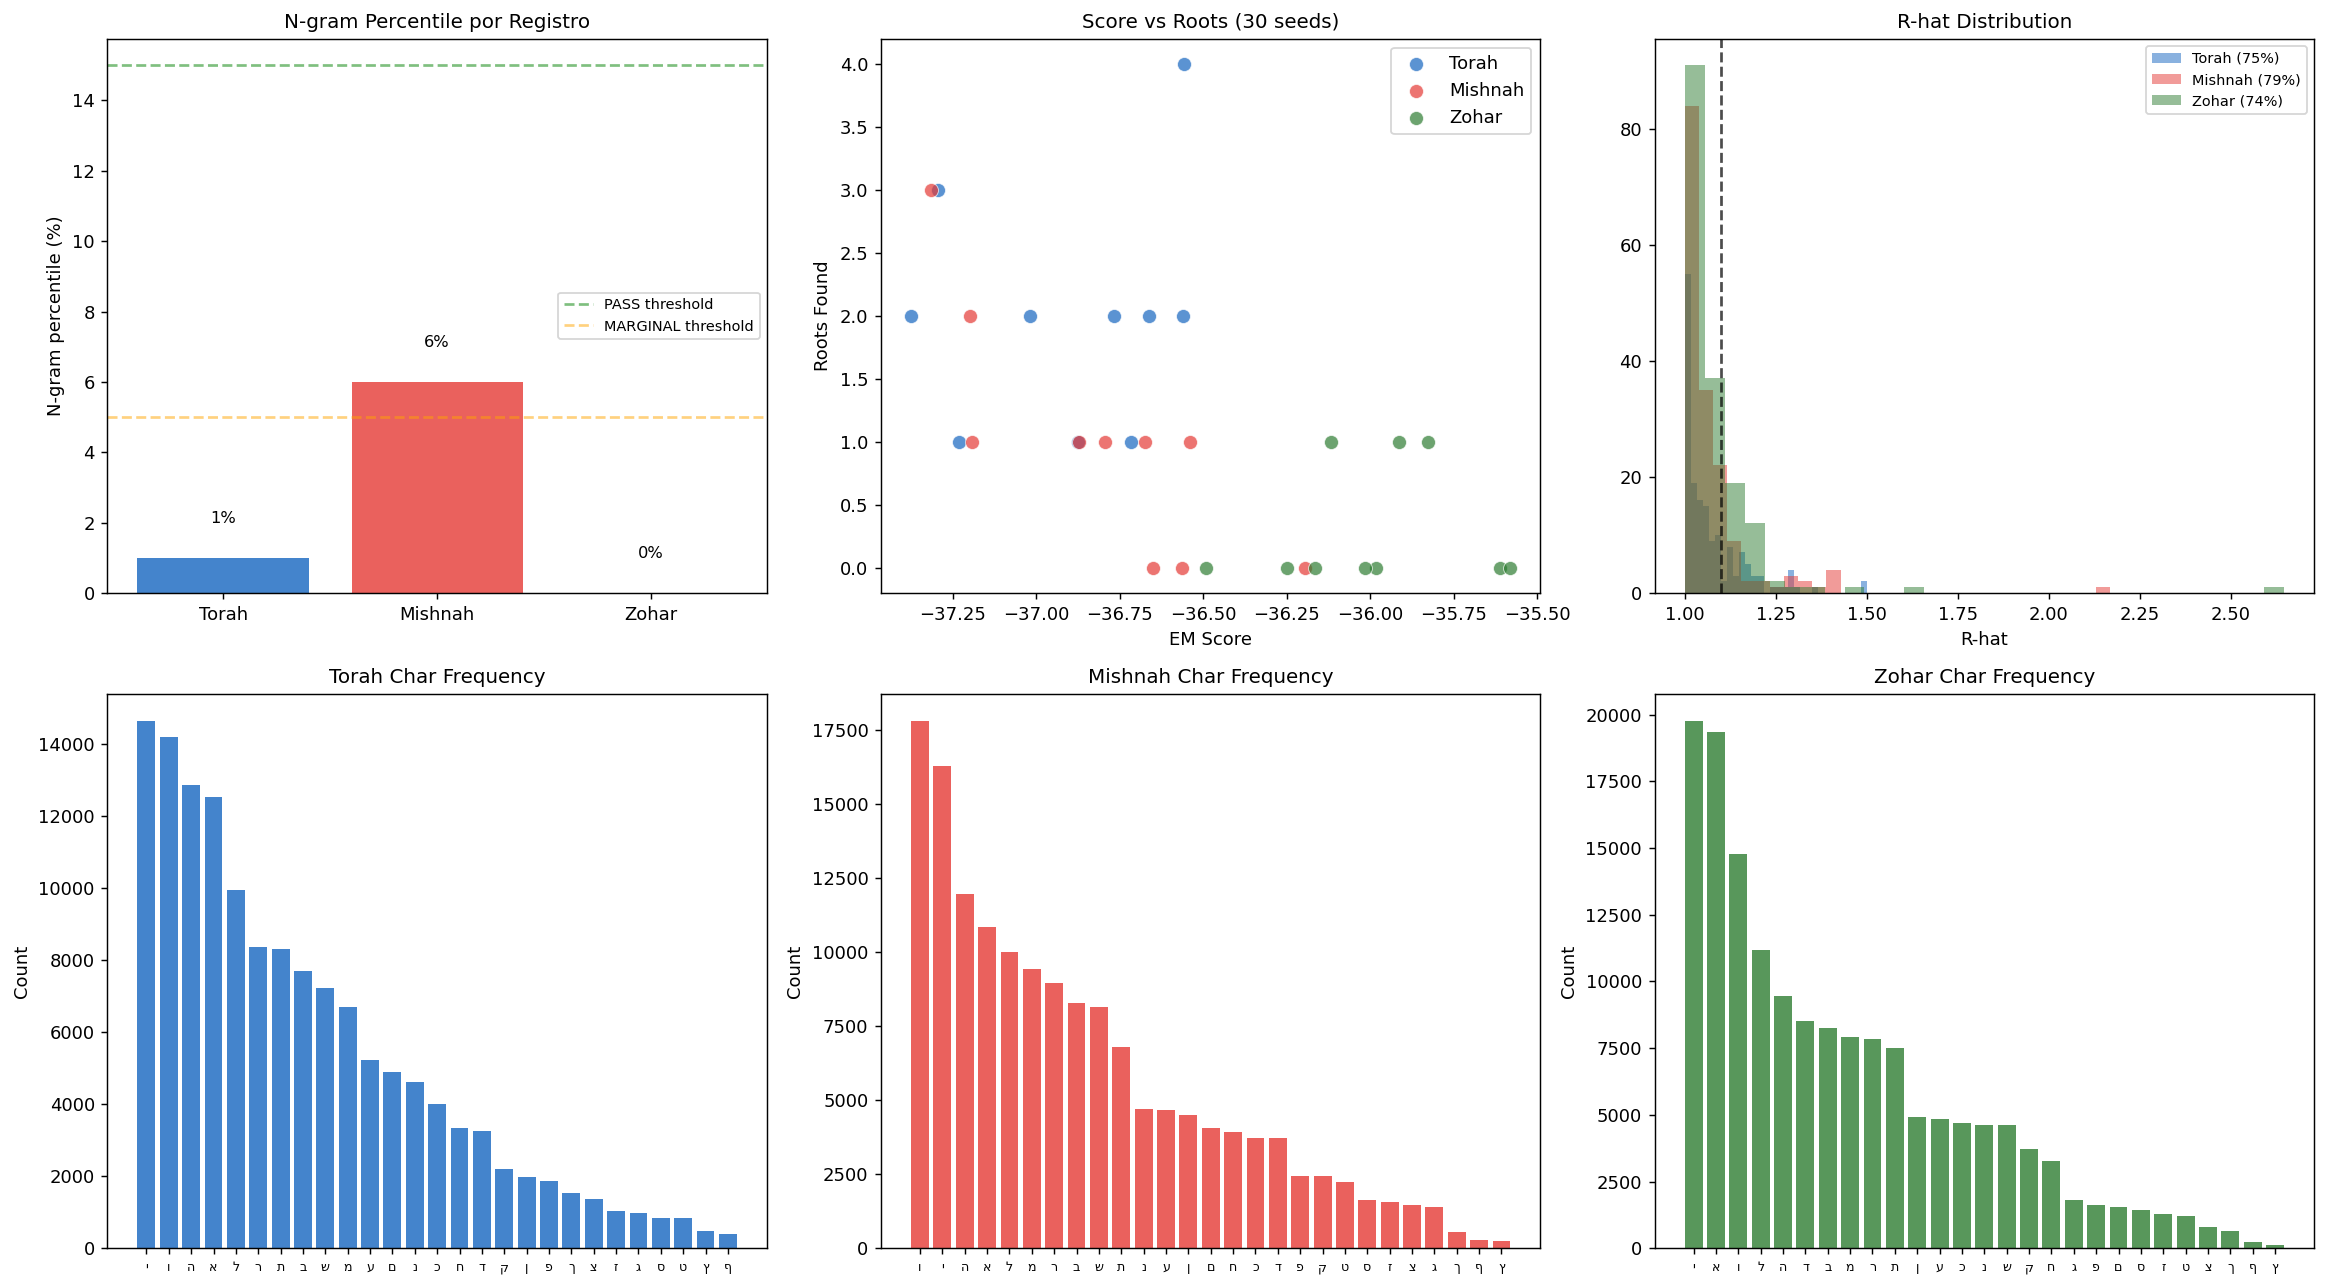

In [12]:
# ── Cell 12: Visualisations ────────────────────────────────────────

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
colors = {'Torah': '#1565C0', 'Mishnah': '#E53935', 'Zohar': '#2E7D32'}

# 1. N-gram percentilee barplot
ax = axes[0, 0]
names = ['Torah', 'Mishnah', 'Zohar']
vals = [validation_all[n]['ngram_percentile'] for n in names]
bars = ax.bar(names, vals, color=[colors[n] for n in names], alpha=0.8)
ax.axhline(15, ls='--', color='green', alpha=0.5, label='PASS threshold')
ax.axhline(5, ls='--', color='orange', alpha=0.5, label='MARGINAL threshold')
ax.set_ylabel('N-gram percentile (%)')
ax.set_title('N-gram Percentile by Register')
ax.legend(fontsize=8)
for bar, val in zip(bars, vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f'{val:.0f}%', ha='center', fontsize=9)

# 2. Scatter: score vs roots (all 30 seeds)
ax = axes[0, 1]
for reg_name in names:
    scores = [r['score'] for r in all_register_results[reg_name]]
    roots = [r['n_roots'] for r in all_register_results[reg_name]]
    ax.scatter(scores, roots, color=colors[reg_name], label=reg_name,
               alpha=0.7, s=60, edgecolors='white', linewidth=0.5)
ax.set_xlabel('EM Score')
ax.set_ylabel('Roots Found')
ax.set_title('Score vs Roots (30 seeds)')
ax.legend()

# 3. Character frequency per corpus
for ci, reg_name in enumerate(names):
    ax = axes[1, ci]
    words = corpora[reg_name]
    char_freq = Counter(c for w in words for c in w)
    chars_sorted = sorted(char_freq.keys(), key=lambda c: char_freq[c], reverse=True)
    freqs = [char_freq[c] for c in chars_sorted]
    ax.bar(range(len(chars_sorted)), freqs, color=colors[reg_name], alpha=0.8)
    ax.set_xticks(range(len(chars_sorted)))
    ax.set_xticklabels(chars_sorted, fontsize=7)
    ax.set_title(f'{reg_name} Char Frequency')
    ax.set_ylabel('Count')

# 4. R-hat distributions
ax = axes[0, 2]
for reg_name in names:
    rhat_vals = [v for v in validation_all[reg_name]['rhat'].values()
                 if isinstance(v, (int, float)) and not np.isnan(v) and not np.isinf(v)]
    ax.hist(rhat_vals, bins=30, alpha=0.5, color=colors[reg_name],
            label=f'{reg_name} ({validation_all[reg_name]["pct_converged"]:.0f}%)')
ax.axvline(1.1, ls='--', color='black', alpha=0.7)
ax.set_xlabel('R-hat')
ax.set_title('R-hat Distribution')
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

Vocab overlap:
  Union: 27 chars
  Intersection: 27 chars
  Torah: 27 chars
  Mishnah: 27 chars
  Zohar: 27 chars


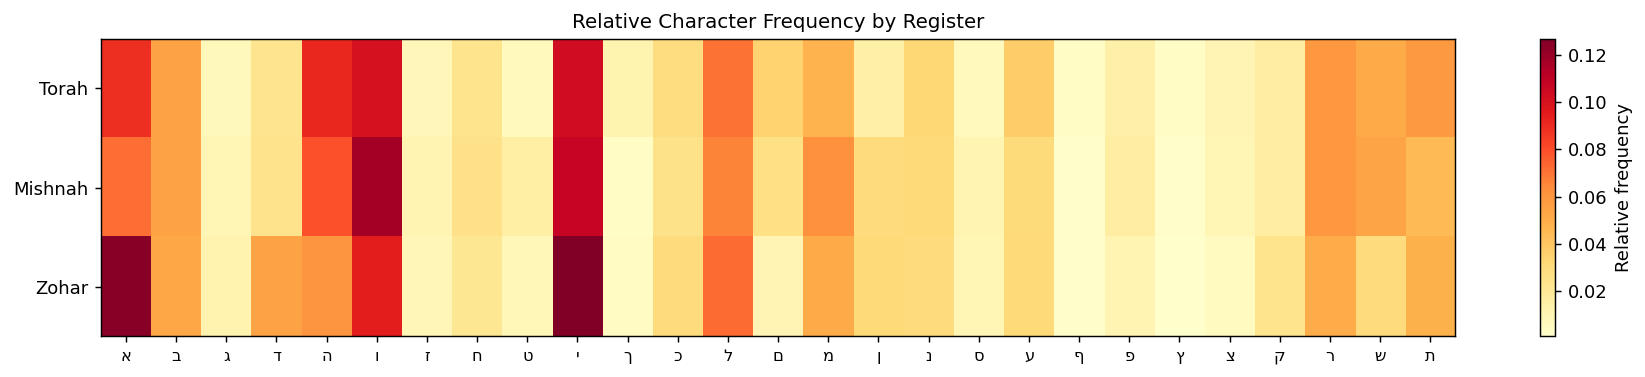

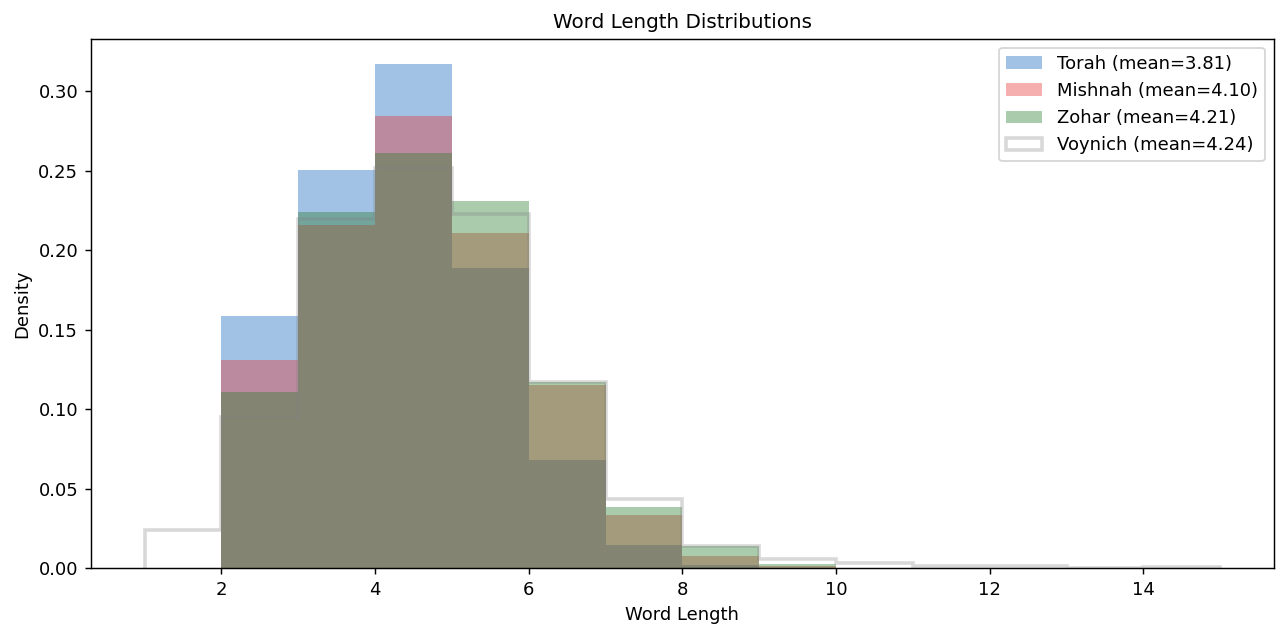

In [13]:
# ── Cell 13: Character analysis ─────────────────────────────────

# 1. Vocabulary overlap
vocabs = {name: set(c for w in words for c in w) for name, words in corpora.items()}
all_chars_union = vocabs['Torah'] | vocabs['Mishnah'] | vocabs['Zohar']
all_chars_inter = vocabs['Torah'] & vocabs['Mishnah'] & vocabs['Zohar']
print(f'Vocab overlap:')
print(f'  Union: {len(all_chars_union)} chars')
print(f'  Intersection: {len(all_chars_inter)} chars')
for name, v in vocabs.items():
    unique = v - (all_chars_union - v)
    print(f'  {name}: {len(v)} chars')

# 2. Character frequency heatmap
all_chars_sorted = sorted(all_chars_inter)
freq_matrix = np.zeros((3, len(all_chars_sorted)))
reg_names = ['Torah', 'Mishnah', 'Zohar']
for ri, name in enumerate(reg_names):
    total = sum(len(w) for w in corpora[name])
    cf = Counter(c for w in corpora[name] for c in w)
    for ci, ch in enumerate(all_chars_sorted):
        freq_matrix[ri, ci] = cf.get(ch, 0) / total

fig, ax = plt.subplots(figsize=(14, 3))
im = ax.imshow(freq_matrix, aspect='auto', cmap='YlOrRd')
ax.set_yticks(range(3))
ax.set_yticklabels(reg_names)
ax.set_xticks(range(len(all_chars_sorted)))
ax.set_xticklabels(all_chars_sorted, fontsize=9)
ax.set_title('Relative Character Frequency by Register')
plt.colorbar(im, ax=ax, label='Relative frequency')
plt.tight_layout()
plt.show()

# 3. Word length distributions
fig, ax = plt.subplots(figsize=(10, 5))
colors_wl = {'Torah': '#1565C0', 'Mishnah': '#E53935', 'Zohar': '#2E7D32'}
for name in reg_names:
    wls = [len(w) for w in corpora[name]]
    ax.hist(wls, bins=range(1, 16), alpha=0.4, color=colors_wl[name],
            label=f'{name} (mean={np.mean(wls):.2f})', density=True)
# Decoded word lengths
for name in reg_names:
    mapping = dict(mcmc_results_all[name]['best_state'].mapping)
    decoded = [len([mapping.get(g, '?') for g in w]) for w in palabras[:5000]]
    # decoded is same as Voynich word lengths since it's char-level
voynich_wls = [len(w) for w in palabras]
ax.hist(voynich_wls, bins=range(1, 16), alpha=0.3, color='gray',
        label=f'Voynich (mean={np.mean(voynich_wls):.2f})', density=True,
        histtype='step', linewidth=2)
ax.set_xlabel('Word Length')
ax.set_ylabel('Density')
ax.set_title('Word Length Distributions')
ax.legend()
plt.tight_layout()
plt.show()

In [14]:
# ── Cell 14: Statistical test — Bootstrap CI ───────────────────────

print('Bootstrap CI for n-gram percentile differences between registers')
print('='*70)

# Re-run null shuffles with bootstrap to get CIs
N_BOOTSTRAP = 500
rng_boot = np.random.default_rng(42)

register_ngram_bootstraps = {}

for reg_name in ['Torah', 'Mishnah', 'Zohar']:
    mapping = dict(mcmc_results_all[reg_name]['best_state'].mapping)
    target_chars = trained_lms[reg_name]['target_chars']
    char_role = trained_lms[reg_name]['char_role']

    state_v = GlyphMappingState(VOCAB, target_chars, glyph_role, char_role)
    state_v.set_mapping(mapping)

    reg_sample = corpora[reg_name][:5000]
    voynich_sample = palabras[:5000]
    ref_dist = corpus_trigram_distribution(reg_sample)
    mapped_real = [state_v.apply_word(w) for w in voynich_sample]
    real_dist = corpus_trigram_distribution(mapped_real)
    real_jsd = trigram_jsd(real_dist, ref_dist)

    all_mapped_chars = list(set(mapping.values()))
    boot_pcts = []
    for b in range(N_BOOTSTRAP):
        # Resample null distribution
        null_jsds = []
        for _ in range(50):
            shuf = {g: rng_boot.choice(all_mapped_chars) for g in mapping}
            ss = GlyphMappingState(VOCAB, target_chars, glyph_role, char_role)
            ss.set_mapping(shuf)
            mapped_s = [ss.apply_word(w) for w in voynich_sample]
            null_jsds.append(trigram_jsd(corpus_trigram_distribution(mapped_s), ref_dist))
        pct = 100 * (1 - np.mean([real_jsd < nj for nj in null_jsds]))
        boot_pcts.append(pct)

    register_ngram_bootstraps[reg_name] = boot_pcts
    ci_lo, ci_hi = np.percentile(boot_pcts, [2.5, 97.5])
    print(f'  {reg_name}: n-gram %ile = {np.mean(boot_pcts):.1f}% '
          f'[{ci_lo:.1f}%, {ci_hi:.1f}%] (95% CI)')

# Pairwise differences
print(f'\nPairwise differences (bootstrap):')
for a, b in [('Mishnah', 'Torah'), ('Zohar', 'Torah'), ('Zohar', 'Mishnah')]:
    diffs = np.array(register_ngram_bootstraps[a]) - np.array(register_ngram_bootstraps[b])
    ci_lo, ci_hi = np.percentile(diffs, [2.5, 97.5])
    sig = 'SIGNIFICATIVO' if (ci_lo > 0 or ci_hi < 0) else 'no significativo'
    print(f'  {a} - {b}: mean={np.mean(diffs):.1f}pp [{ci_lo:.1f}, {ci_hi:.1f}] -> {sig}')

Bootstrap CI for n-gram percentile differences between registers
  Torah: n-gram %ile = 1.0% [0.0%, 4.0%] (95% CI)
  Mishnah: n-gram %ile = 8.1% [2.0%, 16.0%] (95% CI)
  Zohar: n-gram %ile = 0.0% [0.0%, 0.0%] (95% CI)

Pairwise differences (bootstrap):
  Mishnah - Torah: mean=7.1pp [0.0, 16.0] -> no significativo
  Zohar - Torah: mean=-0.9pp [-4.0, 0.0] -> no significativo
  Zohar - Mishnah: mean=-8.0pp [-16.0, -2.0] -> SIGNIFICATIVO


In [15]:
# ── Cell 15: Export results → registers_resultados.json ────────

class NumpyEncoder(json.JSONEncoder):
    def default(self, obj):
        if isinstance(obj, (np.integer,)): return int(obj)
        if isinstance(obj, (np.floating,)): return float(obj)
        if isinstance(obj, np.ndarray): return obj.tolist()
        if isinstance(obj, set): return sorted(obj)
        return super().default(obj)

resultados = {
    'metadata': {
        'notebook': '19_registers.ipynb',
        'modelo': 'neural_lstm_registers_comparison',
        'description': 'Comparison of 3 Hebrew registers (Torah/Mishnah/Zohar) with neural_v2 pipeline',
        'registers': ['Torah', 'Mishnah', 'Zohar'],
        'n_seeds_per_register': N_SEEDS,
        'T_fixed': T_FIXED,
        'EM_iters': EM_ITERS,
        'MCMC_iter': N_ITER,
    },
    'corpora_stats': {
        name: {
            'full_size': len(corpora_full[name]),
            'sample_size': len(corpora[name]),
            'vocab_size': len(set(c for w in corpora[name] for c in w)),
            'mean_wl': round(float(np.mean([len(w) for w in corpora[name]])), 3),
        } for name in ['Torah', 'Mishnah', 'Zohar']
    },
    'lm_stats': {
        name: {
            'val_loss': round(float(trained_lms[name]['val_loss']), 4),
            'n_chars': len(trained_lms[name]['target_chars']),
            'n_epochs': len(trained_lms[name]['train_losses']),
        } for name in ['Torah', 'Mishnah', 'Zohar']
    },
    'em_results': {
        name: {
            'n_seeds': N_SEEDS,
            'score_mean': round(float(np.mean([r['score'] for r in results])), 4),
            'score_std': round(float(np.std([r['score'] for r in results])), 4),
            'roots_mean': round(float(np.mean([r['n_roots'] for r in results])), 1),
            'roots_std': round(float(np.std([r['n_roots'] for r in results])), 1),
            'roots_max': int(max(r['n_roots'] for r in results)),
            'best_seed': best_per_register[name]['seed'],
            'best_score': round(float(best_per_register[name]['score']), 4),
            'seeds': [{
                'seed': r['seed'],
                'score': round(float(r['score']), 4),
                'K_eff': int(r['K_eff']),
                'n_roots': int(r['n_roots']),
                'roots_list': sorted(r['roots']),
                'grammar': round(float(r['grammar']), 3),
            } for r in results],
        } for name, results in all_register_results.items()
    },
    'mcmc_results': {
        name: {
            'best_score': round(float(mcmc_results_all[name]['best_score']), 4),
            'K_eff': len(set(mcmc_results_all[name]['best_state'].mapping.values())),
            'chain_accept_rates': [round(float(ch['accept_rate']), 3)
                                   for ch in mcmc_results_all[name]['chains']],
        } for name in ['Torah', 'Mishnah', 'Zohar']
    },
    'validation': {
        name: {
            'pct_converged_rhat': round(float(v['pct_converged']), 1),
            'collapse_mean_z': round(float(v['collapse_mean_z']), 3),
            'ngram_percentile': round(float(v['ngram_percentile']), 1),
            'ngram_jsd': round(float(v['ngram_jsd']), 4),
            'roots_matched': len(v['roots_matched']),
            'roots_list': sorted(v['roots_matched']),
            'enrichment': round(float(v['enrichment']), 1),
            'K_used': v['K_used'],
            'K_ratio': round(float(v['K_ratio']), 3),
            'grammar_pct': round(float(v['grammar_pct']), 3),
            'scorecard': {s['Test']: s['Verdict'] for s in v['scorecard']},
            'scorecard_summary': f'{v["n_pass"]}+/{v["n_marg"]}±/{v["n_fail"]}-',
        } for name, v in validation_all.items()
    },
    'cross_scoring': cross_scores,
    'bootstrap_ngram': {
        name: {
            'mean': round(float(np.mean(pcts)), 1),
            'ci_lo': round(float(np.percentile(pcts, 2.5)), 1),
            'ci_hi': round(float(np.percentile(pcts, 97.5)), 1),
        } for name, pcts in register_ngram_bootstraps.items()
    },
    'mappings': {
        name: {g: c for g, c in mcmc_results_all[name]['best_state'].mapping.items()}
        for name in ['Torah', 'Mishnah', 'Zohar']
    },
}

with open('registers_resultados.json', 'w') as f:
    json.dump(resultados, f, indent=2, ensure_ascii=False, cls=NumpyEncoder)
print('Results exported to registers_results.json')
print(f'Keys: {list(results.keys())}')

# ── Final summary ──
print(f'\n{"="*70}')
print('FINAL SUMMARY')
print(f'{"="*70}')
for name in ['Torah', 'Mishnah', 'Zohar']:
    v = validation_all[name]
    print(f'  {name:<10}: n-gram={v["ngram_percentile"]:.0f}%, roots={len(v["roots_matched"])}, '
          f'R-hat={v["pct_converged"]:.0f}%, scorecard={v["n_pass"]}+/{v["n_marg"]}±/{v["n_fail"]}-')

# Conclusion
ngrams = {n: validation_all[n]['ngram_percentile'] for n in ['Torah', 'Mishnah', 'Zohar']}
best_reg = max(ngrams, key=ngrams.get)
worst_reg = min(ngrams, key=ngrams.get)
spread = max(ngrams.values()) - min(ngrams.values())
print(f'\nBest register: {best_reg} ({ngrams[best_reg]:.0f}%)')
print(f'Worst register: {worst_reg} ({ngrams[worst_reg]:.0f}%)')
print(f'Spread: {spread:.0f}pp')
if spread < 15:
    print('Conclusion: registers are indistinguishable — the limit is structural to the Voynich')
elif ngrams[best_reg] > ngrams['Torah'] + 10:
    print(f'Conclusion: {best_reg} significantly outperforms Torah')
else:
    print('Conclusion: marginal differences between registers')

Resultados exportados a registers_resultados.json
Keys: ['metadata', 'corpora_stats', 'lm_stats', 'em_results', 'mcmc_results', 'validation', 'cross_scoring', 'bootstrap_ngram', 'mappings']

FINAL SUMMARY
  Torah     : n-gram=1%, roots=4, R-hat=75%, scorecard=2+/0±/3-
  Mishnah   : n-gram=6%, roots=3, R-hat=79%, scorecard=2+/2±/1-
  Zohar     : n-gram=0%, roots=1, R-hat=74%, scorecard=2+/1±/2-

Best register: Mishnah (6%)
Worst register: Zohar (0%)
Spread: 6pp
Conclusion: registers are indistinguishable — the limit is structural to the Voynich
